<a href="https://colab.research.google.com/github/DheaAprilya/Pengolahan-Citra-Digital/blob/main/PCD6_DheaAprilya_20240040136_TI24A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Nama  : Dhea Aprilya

NIM   : 20240040136

Kelas : TI24E

1.	Siapkan satu gambar dengan format JPG atau PNG.
2.	Implementasikan Translation.
3.	Implementasikan Scaling dengan faktor 0,5 dan 2.
4.	Implementasikan Rotation dengan sudut 45°, 90°, dan 180°.
5.	Implementasikan Horizontal Flip dan Vertical Flip.
6.	Tampilkan citra asli dan seluruh hasil transformasi.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()
nama_file = list(uploaded.keys())[0]

img = cv2.imread(nama_file)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("Ukuran citra asli (tinggi, lebar, channel):", img.shape)

Saving boneka.jpg to boneka.jpg
Ukuran citra asli (tinggi, lebar, channel): (408, 489, 3)


**Translation**

In [3]:
def translasi(image, tx, ty):
    h, w = image.shape[:2]
    M = np.float32([[1, 0, tx],
                    [0, 1, ty]])
    return cv2.warpAffine(image, M, (w, h))

hasil_translasi = translasi(img, 100, 50)

**Scaling (faktor 0,5 dan 2)**

In [4]:
scale_05 = cv2.resize(img, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
scale_2  = cv2.resize(img, None, fx=2,   fy=2,   interpolation=cv2.INTER_CUBIC)

print("Ukuran scaling 0.5:", scale_05.shape)
print("Ukuran scaling 2  :", scale_2.shape)

Ukuran scaling 0.5: (204, 244, 3)
Ukuran scaling 2  : (816, 978, 3)


**Rotation (45°, 90°, 180°)**

In [6]:
def rotasi(image, sudut):
    h, w = image.shape[:2]
    pusat = (w / 2, h / 2)
    M = cv2.getRotationMatrix2D(pusat, sudut, 1.0)

    cos = abs(M[0, 0])
    sin = abs(M[0, 1])
    w_baru = int(h * sin + w * cos)
    h_baru = int(h * cos + w * sin)

    M[0, 2] += (w_baru / 2) - pusat[0]
    M[1, 2] += (h_baru / 2) - pusat[1]

    return cv2.warpAffine(image, M, (w_baru, h_baru))

rot_45  = rotasi(img, 45)
rot_90  = rotasi(img, 90)
rot_180 = rotasi(img, 180)

**Horizontal Flip dan Vertical Flip**

In [7]:
flip_horizontal = cv2.flip(img, 1)
flip_vertical   = cv2.flip(img, 0)

**Tampilkan semua hasil**

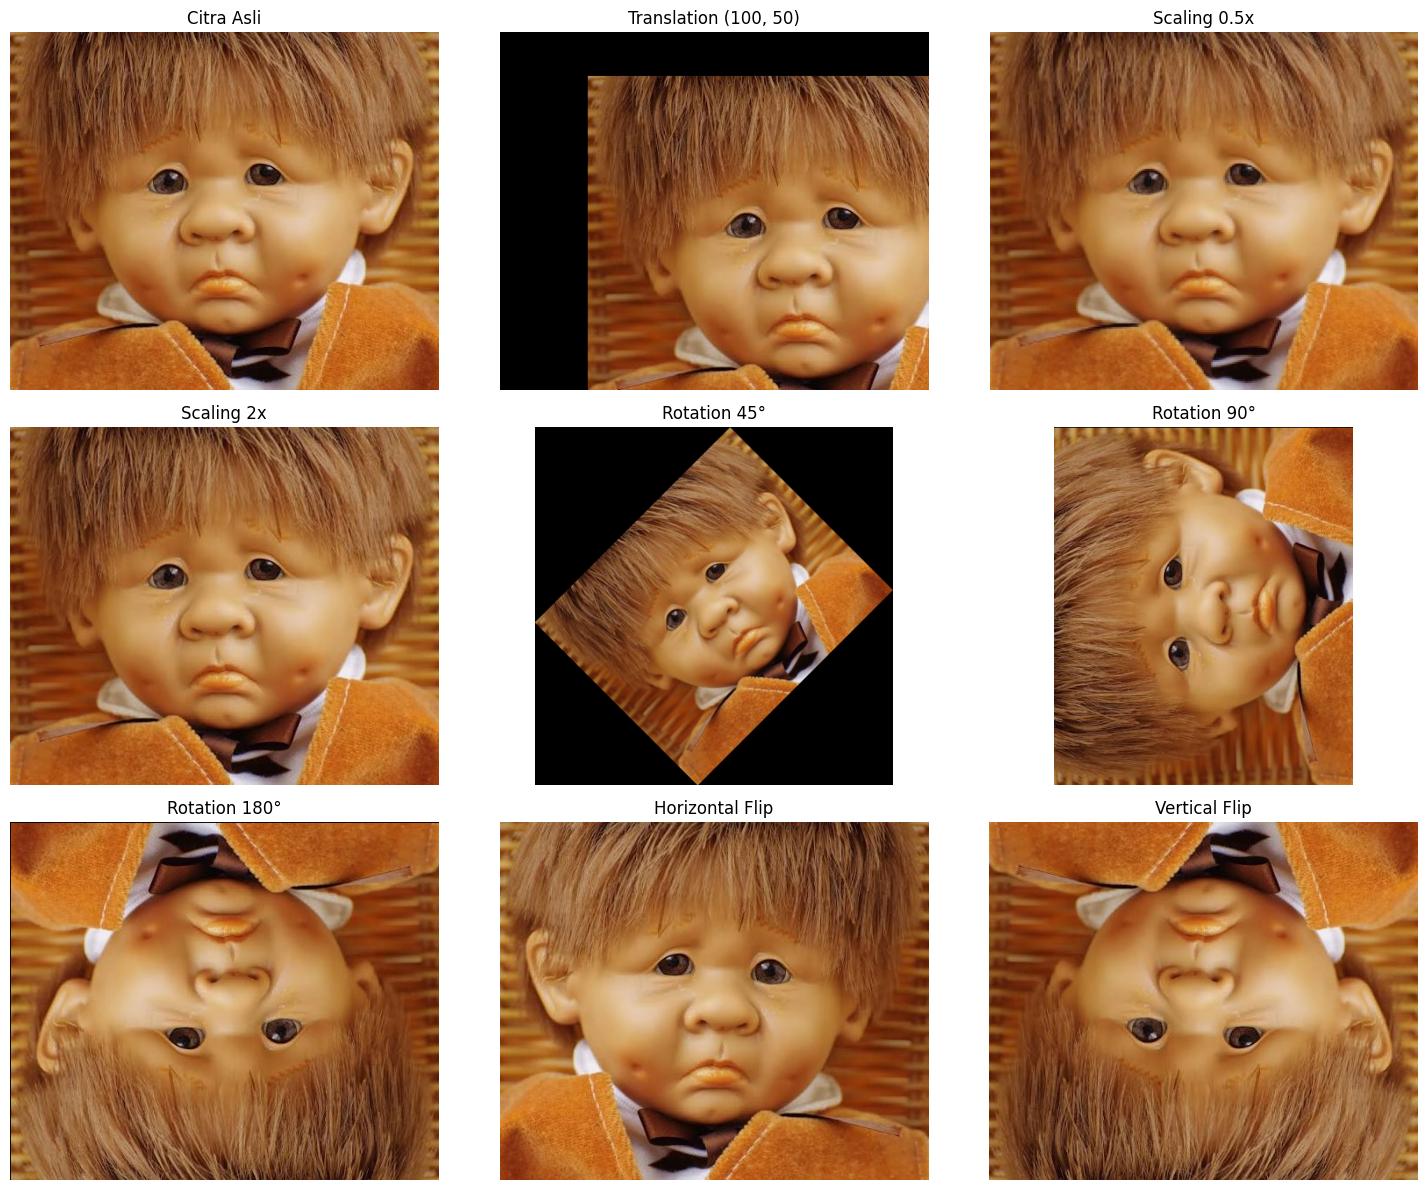

In [8]:
hasil = [
    ("Citra Asli", img),
    ("Translation (100, 50)", hasil_translasi),
    ("Scaling 0.5x", scale_05),
    ("Scaling 2x", scale_2),
    ("Rotation 45°", rot_45),
    ("Rotation 90°", rot_90),
    ("Rotation 180°", rot_180),
    ("Horizontal Flip", flip_horizontal),
    ("Vertical Flip", flip_vertical),
]

plt.figure(figsize=(15, 12))
for i, (judul, gambar) in enumerate(hasil):
    plt.subplot(3, 3, i + 1)
    plt.imshow(gambar)
    plt.title(judul)
    plt.axis("off")

plt.tight_layout()
plt.show()